# SlipCast: exploratory analysis of delivery data

This notebook explores the demo project (a SaaS billing team, about 430 tickets over six
months) using the **same backend services the SlipCast API uses**, so every number here
matches what the app shows for the same day.

Questions:
1. How long does work take, and how skewed is it?
2. How steady is throughput?
3. Where does work pile up?
4. Which types, themes and owners slip most?
5. Do plans, and ticket quality, relate to slipping?

The data is synthetic but generated with patterns real teams show (payments work is slow,
vague tickets slip, an overloaded owner finishes later), so the analysis has something
real to find. Every finding below is computed, not assumed.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="Unknown solver options")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from slipcast_data import NOW, load_demo

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 2)

analysis = load_demo()
t = analysis.tickets.assign(type=analysis.effective_kind, theme=analysis.themes, quality=analysis.quality)
t["owner"] = t["owner"].replace("", "Unassigned")
done = t[t["finished"]]
print(f"{len(t)} tickets, {len(done)} finished, {(t.status != 'done').sum()} open; today = {NOW:%Y-%m-%d}")
t[["title", "type", "theme", "status", "owner", "created_at", "completed_at", "cycle_days", "late"]].head()

430 tickets, 398 finished, 32 open; today = 2026-11-05


,title,type,theme,status,owner,created_at,completed_at,cycle_days,late
0,Allow admins to configure chart legend in CSV ...,feature,"chart, export, csv",done,Meera,2026-05-07 18:23:10.295014,2026-05-18 04:49:56.049373,6.11,0.0
1,Show connection pool on Kubernetes deployment,feature,"pipeline, cache, database",done,Karthik,2026-05-07 22:48:08.769241,2026-05-23 00:33:20.930881,11.57,0.0
2,Stark Retail cannot access Redis cache,support,"pipeline, cache, database",done,Priya,2026-05-08 02:26:47.579161,2026-05-14 08:28:31.903545,2.59,1.0
3,Add integration tests for welcome email,tech_debt,"trial, setup, onboarding",done,Priya,2026-05-08 06:41:30.313952,2026-05-17 16:46:48.780437,4.43,NaN
4,Show tax amount on checkout,feature,"invoice, billing, checkout",done,Arun,2026-05-09 03:00:20.197889,2026-05-21 14:43:34.590530,9.64,NaN


## 1. The data at a glance

`type` is the labelled ticket type, or the text classifier's prediction where no label
exists. `theme` comes from K-means clustering on ticket text. `late` is 1 when a ticket
finished after its due date (only defined for finished tickets that had one).

In [2]:
summary = pd.DataFrame({
    "tickets": t.groupby("type").size(),
    "finished": done.groupby("type").size(),
    "labelled": t[t.kind_source == "label"].groupby("type").size(),
}).fillna(0).astype(int)
summary.loc["total"] = summary.sum()
summary

,tickets,finished,labelled
type,,,
bug,163,153,133
feature,131,120,110
support,63,59,48
tech_debt,73,66,56
total,430,398,347


## 2. Cycle time: how long work really takes

Cycle time is the time from starting a ticket to finishing it. Delivery data is almost
always right-skewed: most tickets are quick, a few take much longer. That is why SlipCast
quotes percentiles (P50, P85, P95) instead of averages.

mean 7.1 d vs median 5.7 d; skewness 2.78


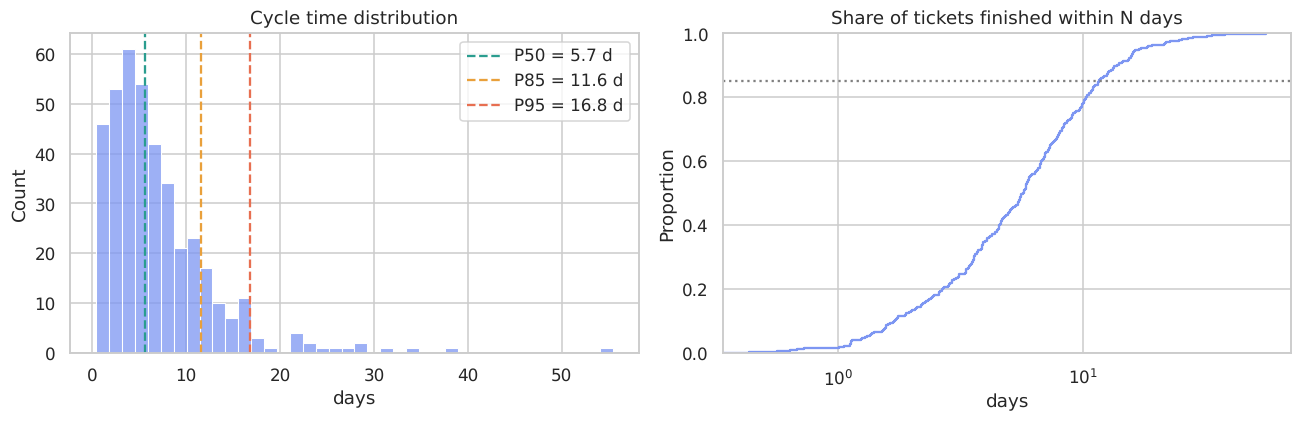

In [3]:
p50, p85, p95 = np.percentile(done.cycle_days, [50, 85, 95])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(done.cycle_days, bins=40, ax=axes[0], color="#7D96F2")
for v, lab, c in [(p50, "P50", "#2a9d8f"), (p85, "P85", "#e9a03b"), (p95, "P95", "#e76f51")]:
    axes[0].axvline(v, ls="--", c=c, label=f"{lab} = {v:.1f} d")
axes[0].set(title="Cycle time distribution", xlabel="days")
axes[0].legend()
sns.ecdfplot(done.cycle_days, ax=axes[1], color="#7D96F2")
axes[1].axhline(0.85, ls=":", c="grey")
axes[1].set(title="Share of tickets finished within N days", xlabel="days", xscale="log")
plt.tight_layout()
print(f"mean {done.cycle_days.mean():.1f} d vs median {p50:.1f} d; skewness {done.cycle_days.skew():.2f}")

The mean (about 7 days) sits above the median (under 6) and skewness is strongly positive
(about 2.8): a handful of very long tickets drag the average up. Promising "the average" would be missed far more than half the
time. **The P85 is the honest answer to "when will this ticket be done?"**

,count,50%,85%,max
type,,,,
support,59.0,2.46,5.99,21.59
bug,153.0,4.54,8.95,38.01
tech_debt,66.0,6.81,13.25,29.26
feature,120.0,8.32,15.44,55.42


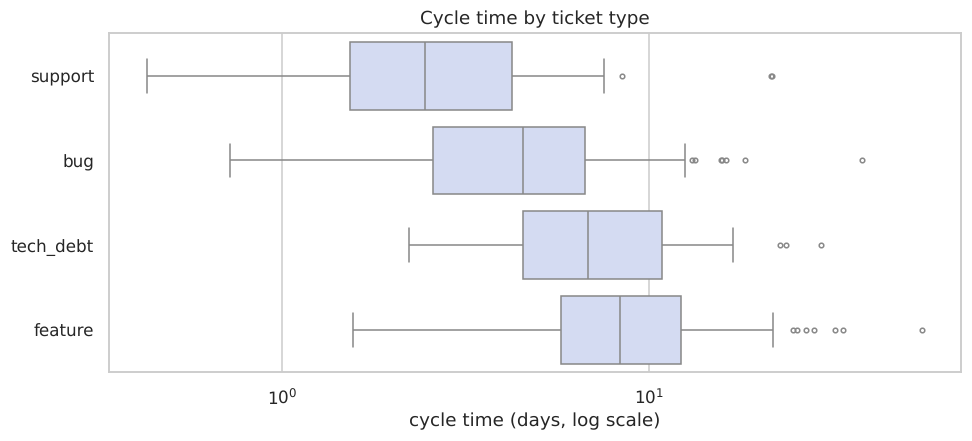

In [4]:
order = done.groupby("type").cycle_days.median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=done, x="cycle_days", y="type", order=order, ax=ax, color="#cfd8f7", fliersize=3)
ax.set(xscale="log", xlabel="cycle time (days, log scale)", ylabel="", title="Cycle time by ticket type")
done.groupby("type").cycle_days.describe(percentiles=[0.5, 0.85])[["count", "50%", "85%", "max"]].sort_values("50%")

Support tickets are fastest and features slowest, with wide spread inside every type. A
single "estimate per type" would still be poor, which is why SlipCast's reference-class
forecast uses the most similar tickets by text rather than the type alone.

## 3. Throughput: how much gets finished each week

last 12 weeks: mean 16.3, sd 3.2, min 12, max 23


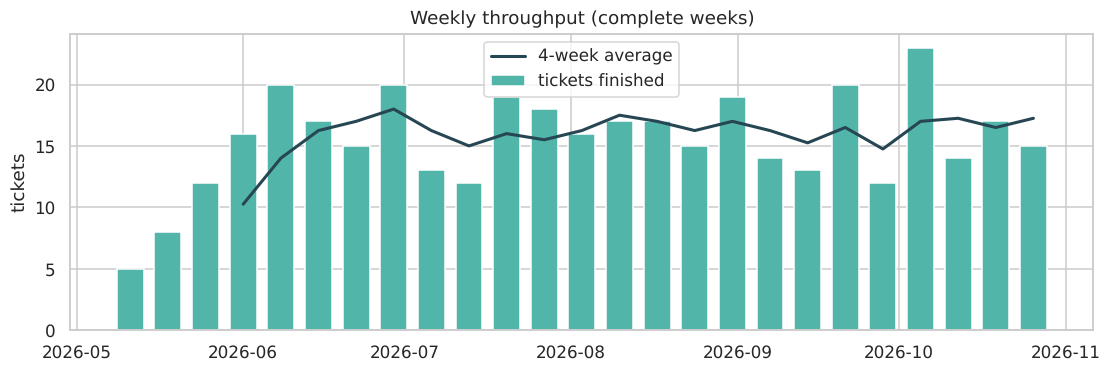

In [5]:
tp = pd.Series(analysis.flow["throughput"]["counts"], index=pd.to_datetime(analysis.flow["throughput"]["weeks"]))
complete = tp.iloc[:-1]  # the last week is still in progress
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(complete.index, complete.values, width=5, color="#52B5AA", label="tickets finished")
ax.plot(complete.index, complete.rolling(4).mean(), c="#264653", lw=2, label="4-week average")
ax.set(title="Weekly throughput (complete weeks)", ylabel="tickets")
ax.legend()
last12 = complete.iloc[-12:]
print(f"last 12 weeks: mean {last12.mean():.1f}, sd {last12.std():.1f}, min {last12.min()}, max {last12.max()}")

After a ramp-up in the first weeks, throughput settles into a stable band. The Monte Carlo
forecast resamples exactly these last 12 complete weeks, so the spread you see here becomes
the spread of the forecast dates.

## 4. Cumulative flow: where work piles up

work in progress: 14 at the start of the window, 16 today, max 24


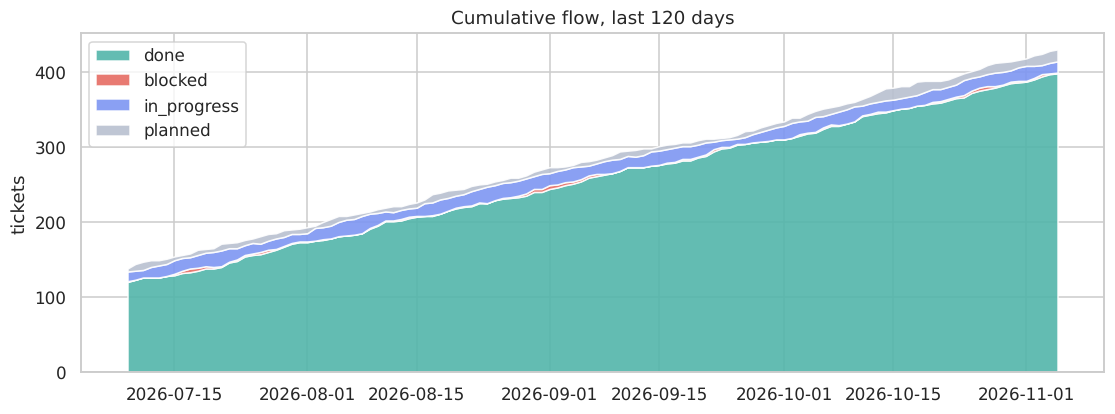

In [6]:
cfd = analysis.flow["cfd"]
dates = pd.to_datetime(cfd["dates"])
fig, ax = plt.subplots(figsize=(12, 4))
layers = ["done", "blocked", "in_progress", "planned"]
colors = ["#52B5AA", "#E66C63", "#7D96F2", "#B8C0D0"]
ax.stackplot(dates, *[cfd["series"][s] for s in layers], labels=layers, colors=colors, alpha=0.9)
ax.set(title="Cumulative flow, last 120 days", ylabel="tickets")
ax.legend(loc="upper left")
wip = np.array(cfd["series"]["in_progress"]) + np.array(cfd["series"]["blocked"])
print(f"work in progress: {wip[0]} at the start of the window, {wip[-1]} today, max {wip.max()}")

The bands for in-progress and blocked work stay thin and roughly parallel, so work is not
piling up in the system overall. The risk is in individual tickets, which the next sections
look at.

## 5. Who and what slips?

Slip rate = share of finished tickets (with a due date) that finished after it. Counts are
shown next to every rate because small groups produce noisy rates.

,finished,slip_rate,median_days
theme,,,
"pipeline, cache, database",59,0.63,7.32
"invoice, billing, checkout",64,0.56,7.92
"notification, email, alert",58,0.41,3.98
"two-factor, login, session",54,0.35,5.62
"chart, export, csv",73,0.34,5.51
"trial, setup, onboarding",60,0.32,4.26


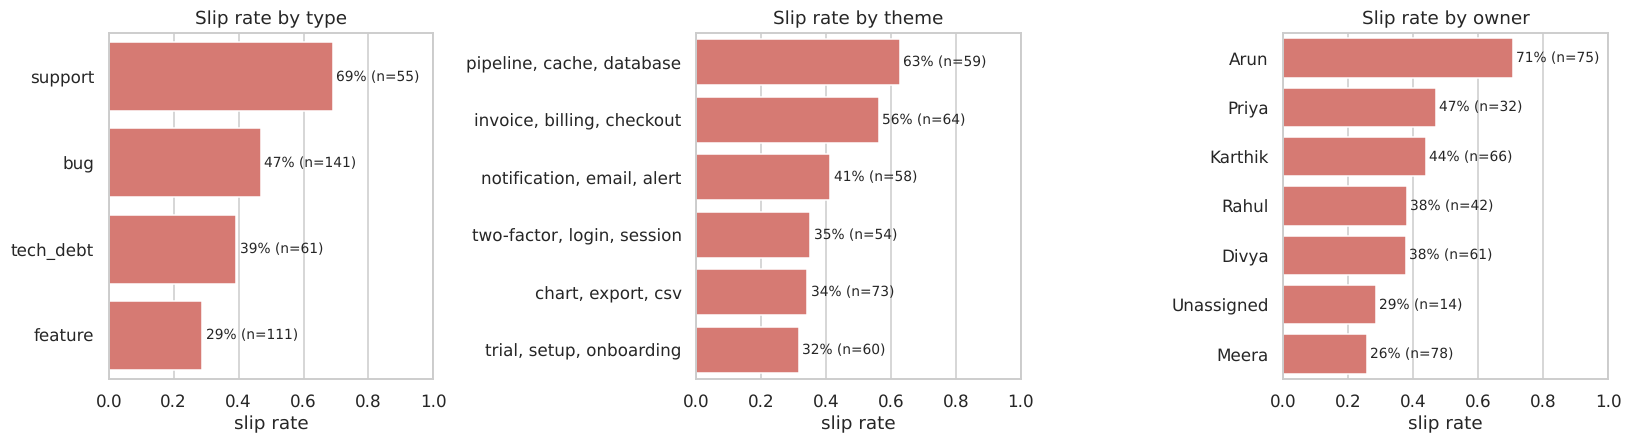

In [7]:
def slip_table(col):
    g = done.dropna(subset=["late"]).groupby(col)
    return pd.DataFrame({"finished": g.size(), "slip_rate": g.late.mean(), "median_days": g.cycle_days.median()}).sort_values("slip_rate", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col in zip(axes, ["type", "theme", "owner"]):
    tab = slip_table(col)
    sns.barplot(x=tab.slip_rate, y=tab.index, ax=ax, color="#E66C63")
    for i, (rate, n) in enumerate(zip(tab.slip_rate, tab.finished)):
        ax.text(rate + 0.01, i, f"{rate:.0%} (n={n})", va="center", fontsize=9)
    ax.set(xlim=(0, 1), xlabel="slip rate", ylabel="", title=f"Slip rate by {col}")
plt.tight_layout()
slip_table("theme")

Two areas stand out: the **infrastructure** theme (pipeline, cache, database) and the
**payments** theme (invoice, billing, checkout) slip most (above 55%) and take longest,
consistent with harder, more often blocked work. By owner, Arun has by far the highest slip
rate (about 70%), and Arun also owns most payments and infrastructure tickets. The next
cell checks whether that is the work or something else.

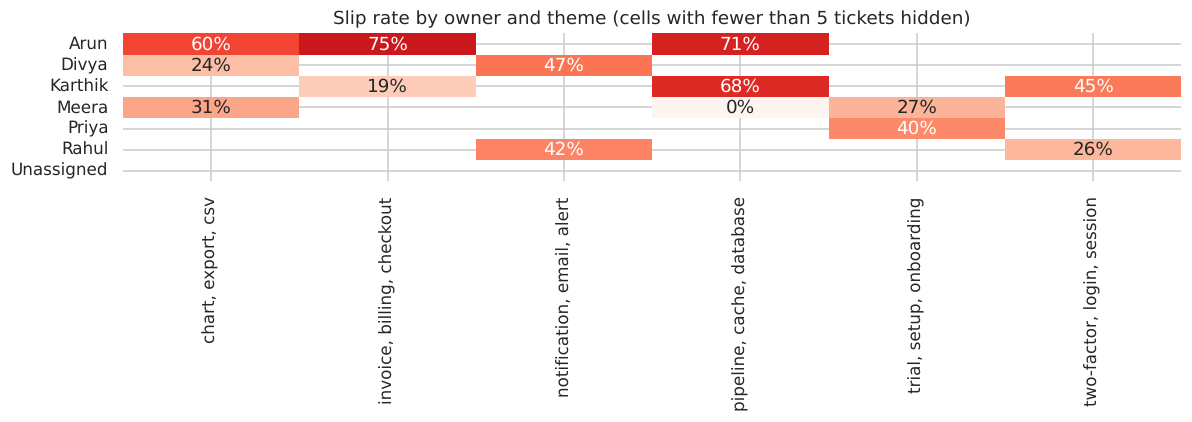

In [8]:
scored = done.dropna(subset=["late"])
rate = scored.pivot_table(index="owner", columns="theme", values="late", aggfunc="mean")
count = scored.pivot_table(index="owner", columns="theme", values="late", aggfunc="size").reindex_like(rate)
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(rate, mask=count.isna() | (count < 5), annot=True, fmt=".0%", cmap="Reds", vmin=0, vmax=1, ax=ax, cbar=False)
ax.set(title="Slip rate by owner and theme (cells with fewer than 5 tickets hidden)", xlabel="", ylabel="")
plt.tight_layout()

It is both. In infrastructure, Arun and Karthik slip at almost the same rate (about 70%), so
there the theme explains it. In payments, Arun slips on about 75% of tickets against about
20% for Karthik on the same theme, so something beyond the work matters. Arun carries the
largest open queue, and an overloaded owner finishing later is a well-known pattern. Cells
with fewer than 5 tickets are hidden because their rates are mostly noise.

This is why SlipCast's risk model uses *workload at creation* as a feature and explains
risk in terms of conditions ("Arun already had 13 open tickets") rather than ranking people.

## 6. Plans versus reality

,mean,size
planned_days,,
"(0, 3]",0.86,42
"(3, 7]",0.54,116
"(7, 14]",0.37,149
"(14, 21]",0.10,61


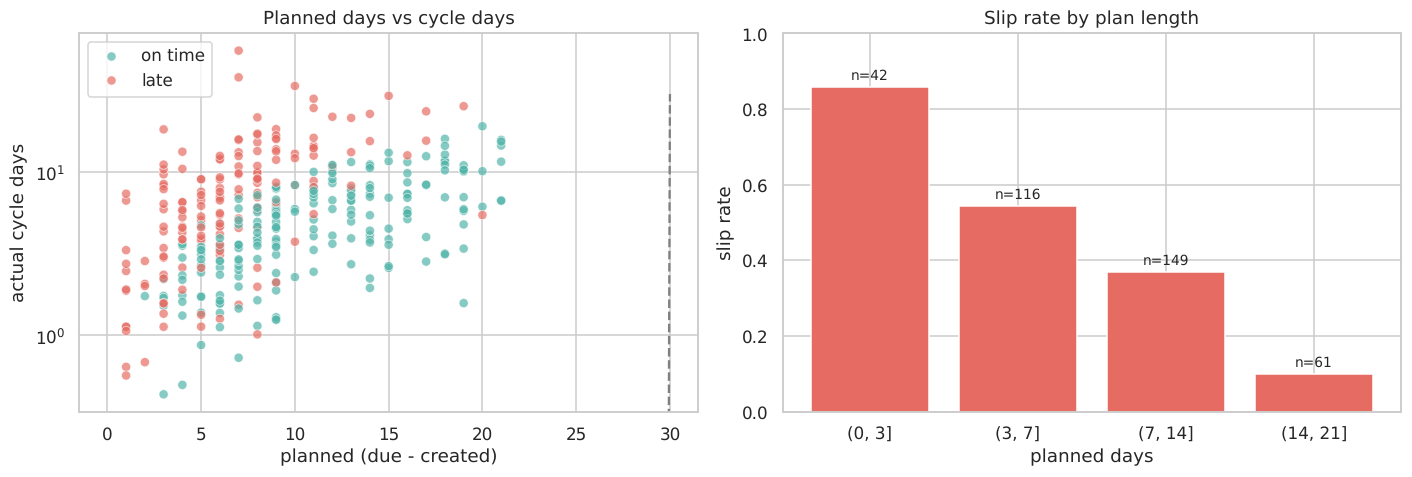

In [9]:
plan = done.dropna(subset=["planned_days", "late"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=plan, x="planned_days", y="cycle_days", hue=plan.late.map({0: "on time", 1: "late"}),
                palette={"on time": "#52B5AA", "late": "#E66C63"}, alpha=0.7, ax=axes[0])
lim = max(plan.planned_days.max(), 30)
axes[0].plot([0, lim], [0, lim], ls="--", c="grey")
axes[0].set(title="Planned days vs cycle days", xlabel="planned (due - created)", ylabel="actual cycle days", yscale="log")
axes[0].legend(title="")
bins = pd.cut(plan.planned_days, [0, 3, 7, 14, 21, 60])
rate = plan.groupby(bins, observed=True).late.agg(["mean", "size"])
axes[1].bar(rate.index.astype(str), rate["mean"], color="#E66C63")
for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
    axes[1].text(i, m + 0.02, f"n={n}", ha="center", fontsize=9)
axes[1].set(title="Slip rate by plan length", xlabel="planned days", ylabel="slip rate", ylim=(0, 1))
plt.tight_layout()
rate

Short plans slip far more often. Note that "late" depends on the plan as much as on the
work: a ticket planned for 3 days that takes 4 is late; one planned for 14 that takes 10 is
not. That makes **plan length the strongest single predictor of slipping**, which the risk
model in notebook 02 confirms. It also motivates the reference-class check: compare the plan
with what similar tickets really took *before* committing to it.

## 7. Ticket quality

,tickets,slip_rate,median_days
quality_band,,,
below 60,57,0.53,7.43
60 or more,311,0.42,5.44


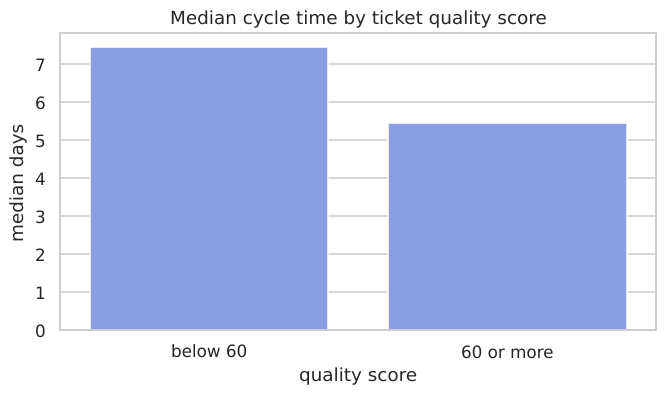

In [10]:
q = done.dropna(subset=["late"]).assign(quality_band=lambda d: pd.cut(d.quality, [-1, 59, 100], labels=["below 60", "60 or more"]))
tab = q.groupby("quality_band", observed=True).agg(tickets=("late", "size"), slip_rate=("late", "mean"), median_days=("cycle_days", "median"))
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=tab.index.astype(str), y=tab.median_days, ax=ax, color="#7D96F2")
ax.set(title="Median cycle time by ticket quality score", xlabel="quality score", ylabel="median days")
tab

Tickets scoring below 60 (vague titles, no description, no acceptance criteria or
reproduction steps) take longer to finish and slip more often than well-written ones. This is the effect SlipCast's
write-time check targets: it shows the quality score and its reasons while the ticket is
still being written.

## Summary

- Cycle time is heavily right-skewed; percentiles, not averages, are the right way to
  communicate it.
- Throughput is stable after ramp-up, which makes a resampling forecast reasonable.
- Infrastructure and payments work slip most; owner differences largely follow the work
  each person is given.
- Short plans and low-quality tickets are the clearest warning signs, and both are known
  before work starts. That is the basis for SlipCast's write-time risk check.

Notebook 02 evaluates the models that turn these patterns into predictions.